In [100]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import datetime
from typing import Tuple
from pybit.unified_trading import HTTP

In [101]:
root = os.getcwd().split('notebooks')[0]
data_folder = os.path.join(root, 'data')
os.makedirs(data_folder, exist_ok = True)
figures_folder = os.path.join(root, 'figures')
os.makedirs(figures_folder, exist_ok = True)

In [102]:
DATE_START_DATA = pd.to_datetime('2020-01-01')
DATE_BUY_CRY = '2021-07-01'
DATE_OPEN_CC = DATE_BUY_CRY
MULT = 1
LEV = 1
FEE_SPOT = 1e-3
FEE_FUT = 5.5e-4
FEE_DELIVERY = 0.0005
CAPITAL = 1000
MIN_DAYS_LEFT = 30 # minimum number of days the futures contract must have to be usable
HOURS_ROLLING_BEFORE_EXPIRY = 0 # number of hours before expiry used to decide when to close the position
FRAC_CAP_FOR_REHEDGE = 1e-2 # maximum fraction of the capital which can stay unhedged in the perpetual C&C before rehedging

# Functions

In [103]:
def get_last_fri(year: int, month: int) -> pd.Timestamp:
    '''
    Function to get the last Friday of the month (Bybit futures expire on the last Friday at 8:00 UTC).

    Args:
        year: Year.
        month: Month.

    Returns:
        last_fri: Last Friday of `month` of `year`.
    '''
    date = pd.Timestamp(year = year, month = month, day = 1) + pd.offsets.MonthEnd(0)
    while date.weekday() != 4:
        date -= pd.Timedelta(value = 1, unit = 'd')
    last_fri = date + pd.Timedelta(value = 8, unit = 'h')
    return last_fri

def get_dict_exp(year_start: int, year_end: int, crypto: str) -> dict:
    '''
    Function to get the expiry date of the futures for several years.

    Args:
        year_start: First year for which to compute the expiries.
        year_end: Last year for which to compute the expiries.
        crypto: Cryptocurrency under study.

    Returns:
        dict_exp: Dictionary with the different expiries.
    '''
    dict_month_codes = {3: 'H', 6: 'M', 9: 'U', 12: 'Z'}
    dict_exp = {}
    for year in range(year_start, year_end + 1):
        for month, code in dict_month_codes.items():
            dict_exp[f'{crypto.upper()}USD{code}{str(year)[-2:]}'] = get_last_fri(year = year, month = month)
    return dict_exp

def get_close(func, symb: str, date_from: pd.Timestamp, date_to: pd.Timestamp, step_days: int = 30) -> pd.Series:
    '''
    Function to get the close. Note: the time refers to the end of the bar.

    Args:
        func: Bybit function to use (e.g., `get_index_price_kline`).
        symb: Symbol of the contract.
        date_from: First date of data.
        date_to: Last date of data.
        step_days: Number of days of data downloaded in a single step.

    Returns:
        close: Series with the close prices.
    '''
    list_df = []
    while date_from < date_to:
        date_end = min(date_from + pd.Timedelta(value = step_days, unit = 'd'), date_to)
        try:
            df_temp = func(category = 'inverse', symbol = symb, interval = 60, start = int(date_from.timestamp()*1e3),
                           end = int(date_end.timestamp()*1e3), limit = 1000)
            list_df.append(pd.DataFrame(df_temp['result']['list']))
        except Exception as e:
            print(f'{symb}: {e}')
            return pd.Series(dtype = float, name = symb)
        date_from = date_end
    df_temp = pd.concat(list_df) if len(list_df) > 0 else pd.DataFrame()
    if len(df_temp) == 0:
        return pd.Series(dtype = float, name = symb)
    # get_kline has 7 columns, get_index_price_kline 5 -> keep the first 5
    df_temp = df_temp.iloc[:, :5].drop_duplicates()
    df_temp.columns = ['Time', 'Open', 'High', 'Low', 'Close']
    df_temp['Time'] = pd.to_datetime(df_temp['Time'].astype(np.int64)*1e6) + pd.Timedelta(value = 1, unit = 'h')
    df_temp = df_temp.drop_duplicates('Time').set_index('Time').sort_index().astype(float)
    close = df_temp['Close'].rename(symb)
    return close

def get_spot(crypto: str, date_start: pd.Timestamp) -> pd.DataFrame:
    '''
    Function to get the hourly index price, used as spot by both strategies. Note: the time refers to the end of the bar.

    Args:
        crypto: Name of the cryptocurrency (e.g., 'BTC' or 'ETH').
        date_start: Start date of the data.

    Returns:
        df_spot: Dataframe with the 'spot' column.
    '''
    file_name = f'df_spot_{crypto}_{date_start:%Y%m%d}.parquet'
    if file_name not in os.listdir(data_folder):
        session = HTTP()
        date_end = pd.to_datetime(datetime.datetime.today().date())
        df_spot = get_close(session.get_index_price_kline, f'{crypto.upper()}USD', date_start, date_end).rename('spot').to_frame()
        df_spot.to_parquet(os.path.join(data_folder, file_name), compression = 'zstd', compression_level = 9)
    else:
        df_spot = pd.read_parquet(os.path.join(data_folder, file_name))
    return df_spot

def get_data_cc(crypto: str, date_start: pd.Timestamp, df_spot: pd.DataFrame) -> Tuple[pd.DataFrame, dict]:
    '''
    Function to get the futures data needed for the backtest of the C&C on dated futures.

    Args:
        crypto: Name of the cryptocurrency (e.g., 'BTC' or 'ETH').
        date_start: Start date of the data.
        df_spot: Dataframe of the spot (needed to align the time index).

    Returns:
        df_fut: Dataframe containing the futures prices (one column per contract).
        dict_exp: Dictionary (e.g., {`'BTCUSDH21': Timestamp('2021-03-26 08:00:00')}`).
    '''
    date_end = pd.to_datetime(datetime.datetime.today().date())
    dict_exp = get_dict_exp(year_start = date_start.year, year_end = date_end.year + 1, crypto = crypto)
    file_name = f'df_cc_fut_{crypto}_{date_start:%Y%m%d}.parquet'
    #
    if file_name not in os.listdir(data_folder):
        session = HTTP()
        # dated futures: each contract is listed about 6 months before expiry
        list_fut = []
        for symb, exp in dict_exp.items():
            date_from = max(exp - pd.Timedelta(value = 200, unit = 'd'), date_start)
            date_to = min(exp, date_end)
            if date_from >= date_to:
                continue
            symb_temp = get_close(session.get_kline, symb, date_from, date_to)
            print(f'{symb}: {len(symb_temp)} bars')
            if len(symb_temp) > 0:
                list_fut.append(symb_temp)
        df_fut = pd.concat(list_fut, axis = 1).sort_index()
        # save the data
        df_fut.to_parquet(os.path.join(data_folder, file_name), compression = 'zstd', compression_level = 9)
    else:
        df_fut = pd.read_parquet(os.path.join(data_folder, file_name))
    #
    df_fut = df_fut.reindex(df_spot.index).ffill(limit = 24)
    # no price after expiry
    for symb in df_fut.columns:
        df_fut.loc[df_fut.index > dict_exp[symb], symb] = np.nan
    #
    return df_fut, dict_exp

def backtest_cc(df_spot: pd.DataFrame, df_fut: pd.DataFrame, df_ret: pd.DataFrame, dict_exp: dict, date_buy_cry: str, capital: float,
                fee_spot: float, fee_fut: float, fee_delivery: float, mult: float, lev: float, min_days_left: int,
                hours_rolling_before_exp: int, strategy: str) -> Tuple[pd.DataFrame, pd.DataFrame]:
    '''
    Function to run the backtest of the cash&carry on dated futures. The futures to use is chosen among a set of candidates.

    Args:
        df_spot: Dataframe with the spot data.
        df_fut: Dataframe with the futures data.
        df_ret: Dataframe with the returns over time of the different futures.
        dict_exp: Dictionary (e.g., {`'BTCUSDH21': Timestamp('2021-03-26 08:00:00')}`).
        date_buy_cry: Start date of the operation.
        capital: Initial capital.
        fee_spot: Fees for the spot (expressed as a decimal, not as a percentage).
        fee_fut: Fees for the futures (expressed as a decimal, not as a percentage).
        fee_delivery: Fees for the settlement of the futures (expressed as a decimal, not as a percentage).
        mult: Multiplier for the inverse dated futures (depends on the exchange).
        lev: Leverage to use on the futures.
        min_days_left: Minimum number of days left for a futures to be a valid candidate.
        hours_rolling_before_exp: Minimum number of hours left before expiry; past this value, the position is closed.
                                  If set to 0, the position is held until expiry.
        strategy: Strategy used to open the contract: if `max_ret`, the contract with the maximum return is opened; if `first`,
                  the one with the nearest expiry.

    Returns:
        df_cc: Dataframe containing the results of the backtest (equity, etc.).
        df_trade: Dataframe containing the list of the opened positions.
    '''
    if strategy not in ('max_ret', 'first'):
        raise ValueError(f"Strategy '{strategy}' not valid: use 'max_ret' or 'first'.")
    #
    df_cc = df_spot.loc[date_buy_cry:].copy()
    price_buy_spot = df_cc['spot'].values[0]
    port = capital/price_buy_spot*(1 - fee_spot)
    #
    in_pos = False
    symb, n_c, price_open_fut, date_open, equity_in = None, 0, np.nan, None, np.nan
    #
    list_symb, list_fut, list_n_c, list_port, list_pl_unreal, list_equity_cry, list_equity_tot, list_equity_tot_net, list_ret = [], [], [], [], [], [], [], [], []
    list_trade = []
    for date, price_spot in zip(df_cc.index, df_cc['spot'].values):
        # close position
        if in_pos == True:
            exp = dict_exp[symb]
            # less than `hours_rolling_before_exp` hours left before expiry
            if date >= exp - pd.Timedelta(value = hours_rolling_before_exp, unit = 'h'):
                if (hours_rolling_before_exp == 0) or (np.isnan(df_fut.loc[date, symb])):
                    # at expiry, the futures is quoted as the spot
                    price_close, fee = price_spot, fee_delivery
                else:
                    price_close, fee = df_fut.loc[date, symb], fee_fut
                # P&L of the futures
                pl_fut = mult*n_c*(1/price_close - 1/price_open_fut)
                # update of the portfolio
                port += pl_fut - mult*n_c*fee/price_close
                # equity
                equity_end = port*price_spot
                #
                list_trade.append({'symb': symb, 'date_open': date_open, 'date_close': date, 'price_open_fut': price_open_fut,
                                   'price_close': price_close, 'ret_theor_open': ret_theor_open, 'n_c': n_c, 'pl_cry': pl_fut,
                                   'ret_usd': equity_end/equity_in - 1,
                                   'days': (date - date_open)/pd.Timedelta(value = 1, unit = 'd')})
                symb, n_c, price_open_fut = None, 0, np.nan
                #
                in_pos = False

        # open position
        if in_pos == False:
            # list of prices and days to expiry of the possible candidates
            list_prices_cand = df_fut.loc[date].dropna()
            list_symb_cand = pd.Series({symb: (dict_exp[symb] - date)/pd.Timedelta(value = 1, unit = 'd') for symb in list_prices_cand.index}, dtype = float)
            # keep only the candidates with enough days
            list_symb_cand = list_symb_cand[list_symb_cand >= min_days_left]
            # open position
            if len(list_symb_cand) > 0:
                # choose symbol (in `list_symb_cand`, the indices are the symbols)
                if strategy == 'max_ret':
                    symb = df_ret.loc[date, list_symb_cand.index].astype(float).idxmax()
                elif strategy == 'first':
                    symb = list_symb_cand.idxmin()
                #
                price_open_fut = list_prices_cand[symb]
                ret_theor_open = df_ret.loc[date, symb]
                # open futures position
                n_c = np.floor(lev*port*price_open_fut/mult + 1e-6)
                port -= mult*n_c*fee_fut/price_open_fut
                date_open = date
                equity_in = port*price_spot
                #
                in_pos = True

        # P&L evaluation
        if in_pos == True:
            price_fut = df_fut.loc[date, symb]
            if np.isnan(price_fut):
                price_fut = price_spot
            pl_fut = mult*n_c*(1/price_fut - 1/price_open_fut)
            ret = df_ret.loc[date, symb]
        else:
            price_fut, pl_fut, ret = np.nan, 0, np.nan
        # equity
        equity_cry = port + pl_fut
        equity_tot = equity_cry*price_spot
        equity_tot_net = (equity_tot - mult*n_c*fee_fut)*(1 - fee_spot)
        # saving
        list_symb.append(symb)
        list_fut.append(price_fut)
        list_n_c.append(n_c)
        list_port.append(port)
        list_pl_unreal.append(pl_fut)
        list_equity_cry.append(equity_cry)
        list_equity_tot.append(equity_tot)
        list_equity_tot_net.append(equity_tot_net)
        list_ret.append(ret)
    #
    df_cc['symb'] = list_symb
    df_cc['fut'] = list_fut
    df_cc['n_c'] = list_n_c
    df_cc['port'] = list_port
    df_cc['pl_unreal'] = list_pl_unreal
    df_cc['equity_cry'] = list_equity_cry
    df_cc['equity_tot'] = list_equity_tot
    df_cc['equity_tot_net'] = list_equity_tot_net
    df_cc['ret'] = list_ret
    #
    df_trade = pd.DataFrame(list_trade)
    #
    return df_cc, df_trade

In [104]:
def get_funding(crypto: str, date_start: pd.Timestamp, step_days: int = 30) -> pd.DataFrame:
    '''
    Function to get the historical funding rates of the inverse perpetual.

    Args:
        crypto: Name of the cryptocurrency (e.g., 'BTC' or 'ETH').
        date_start: Start date of the data.
        step_days: Number of days downloaded in a single request (with 3 fundings per day, at most 66 so as not to exceed the limit of 200 records).

    Returns:
        df_fund: Dataframe with the 'fund_rate' column.
    '''
    file_name = f'df_fund_{crypto}_{date_start:%Y%m%d}.parquet'
    if file_name not in os.listdir(data_folder):
        session = HTTP()
        date_end = pd.to_datetime(datetime.datetime.today().date())
        list_fund = []
        date_from = date_start
        while date_from < date_end:
            date_to = min(date_from + pd.Timedelta(value = step_days, unit = 'd'), date_end)
            df_temp = session.get_funding_rate_history(category = 'inverse', symbol = f'{crypto.upper()}USD', startTime = int(date_from.timestamp()*1e3),
                                                       endTime = int(date_to.timestamp()*1e3), limit = 200)
            list_fund.append(pd.DataFrame(df_temp['result']['list']))
            date_from = date_to
        # combine the data
        df_fund = pd.concat(list_fund).drop_duplicates().rename(columns = {'fundingRate': 'fund_rate', 'fundingRateTimestamp': 'Time'}).drop('symbol', axis = 1)
        df_fund['Time'] = pd.to_datetime(df_fund['Time'].astype(np.int64)*1e6)
        df_fund = df_fund.set_index('Time').sort_index().astype(float)
        # save the data
        df_fund.to_parquet(os.path.join(data_folder, file_name), compression = 'zstd', compression_level = 9)
    else:
        df_fund = pd.read_parquet(os.path.join(data_folder, file_name))
    return df_fund

def backtest_cc_perp(df: pd.DataFrame, date_buy_cry: str, date_open_cc: str, mult: float, lev: float, fee_spot: float, fee_fut: float, capital: float,
                     frac_cap_for_rehedge: float) -> pd.DataFrame:
    '''
    Function to run a backtest of the C&C on perpetual futures.

    Args:
        df: Dataframe containing the columns 'Close' and 'fund_rate', with time as index.
        date_buy_cry: Purchase date of the spot.
        date_open_cc: Opening date of the short position on the futures.
        mult: Multiplier for the inverse perpetual futures (depends on the exchange).
        lev: Leverage to use on the futures.
        fee_spot: Fees for the spot (expressed as a decimal, not as a percentage).
        fee_fut: Fees for the futures (expressed as a decimal, not as a percentage).
        capital: Initial capital.
        frac_cap_for_rehedge: Fraction of the capital which determines whether to rehedge the position: the rehedge is done when the value (in USD)
                              of the accumulated funding is at least `frac_cap_for_rehedge*capital`.

    Returns:
        df_cc: Dataframe with the results of the backtest.
    '''
    date_buy_cry = pd.to_datetime(date_buy_cry)
    date_open_cc = pd.to_datetime(date_open_cc)
    if date_open_cc < date_buy_cry:
        raise(Exception('The C&C cannot be opened before holding crypto.'))
    # spot purchase
    id_buy_cry = abs((df.index - date_buy_cry).days + (df.index - date_buy_cry).seconds/3600/24).argmin()
    id_buy_cry = df.index[id_buy_cry]
    df_cc = df.loc[id_buy_cry:].copy()
    price_buy_spot = df_cc['Close'].values[0]
    quant_cry_init = capital/price_buy_spot*(1 - fee_spot)
    # C&C opening
    id_open_cc = abs((df_cc.index - date_open_cc).days + (df_cc.index - date_open_cc).seconds/3600/24).argmin()
    id_open_cc = df_cc.index[id_open_cc]
    df_cc = df_cc.loc[id_open_cc:].copy()
    price_avg_entry_fut = df_cc['Close'].values[0]
    # number of contracts for the short on the futures
    n_c = np.floor(lev*quant_cry_init*price_avg_entry_fut/mult + 1e-6)
    # net value of the portfolio
    port_in = quant_cry_init - mult*n_c*fee_fut/price_avg_entry_fut
    #
    list_dates = df_cc.index.values
    list_close = df_cc['Close'].values
    list_fund_rate = df_cc['fund_rate'].fillna(0).values
    list_fund_rate[0] = 0
    #
    (list_funding, list_port, list_pl_fut, list_equity_port, list_equity_fut, list_equity_tot_gross, list_equity_tot_net,
     list_rehedge, list_date_rehedge) = [], [], [], [], [], [], [], [], []
    funding_unhedged = 0
    for i, (date, close, fund_rate) in enumerate(zip(list_dates, list_close, list_fund_rate)):
        # funding
        funding = mult*n_c*fund_rate/close
        list_funding.append(funding)
        funding_unhedged += funding
        # P&L from the futures
        pl_fut = mult*n_c*(1/close - 1/price_avg_entry_fut)
        # number of futures contracts which can be hedged with the accumulated funding
        delta_n_c = np.floor(lev*close/mult*funding_unhedged + 1e-6)
        # value of `delta_n_c` in USD
        val_usd_delta_n_c = delta_n_c*mult
        # rehedge the position on the futures
        if (delta_n_c >= 1) and (val_usd_delta_n_c/capital >= frac_cap_for_rehedge):
            list_rehedge.append([delta_n_c, close])
            # update of the average entry price
            price_avg_entry_fut = (n_c + delta_n_c)/(n_c/price_avg_entry_fut + delta_n_c/close)
            # update of the number of contracts
            n_c += delta_n_c
            # update of the total funding left unhedged
            funding_unhedged -= delta_n_c*mult/(lev*close)
            # mark the rehedge times
            list_date_rehedge.append(date)
        # rehedge fees paid up to now
        fee_rehedge = mult*fee_fut*np.array([delta/close for delta, close in list_rehedge]).sum()
        # value of the portfolio
        port = port_in + np.sum(list_funding) - fee_rehedge
        #
        equity_port = port*close
        equity_fut = pl_fut*close
        equity_tot_gross = equity_port + equity_fut
        equity_tot_net = (1 - fee_spot)*(equity_tot_gross - mult*n_c*fee_fut)
        #
        list_port.append(port)
        list_pl_fut.append(pl_fut)
        list_equity_port.append(equity_port)
        list_equity_fut.append(equity_fut)
        list_equity_tot_gross.append(equity_tot_gross)
        list_equity_tot_net.append(equity_tot_net)
    #
    df_cc['funding'] = list_funding
    df_cc['port'] = list_port
    df_cc['pl_fut'] = list_pl_fut
    df_cc['equity_fut'] = list_equity_fut
    df_cc['equity_port'] = list_equity_port
    df_cc['equity_tot_gross'] = list_equity_tot_gross
    df_cc['equity_tot_net'] = list_equity_tot_net
    df_cc['rehedge'] = np.where(df_cc.index.isin(list_date_rehedge), 1, 0)
    #
    return df_cc

In [105]:
def get_equity_port(equity_1: pd.Series, equity_2: pd.Series, capital: float) -> Tuple[pd.Series, pd.Series]:
    '''
    Function to get the portfolio equity which combines the equities obtained with the dated C&C and the perpetual C&C. The two equities can have
    different frequencies.

    Args:
        equity_1: First of the two equities.
        equity_2: Second of the two equities.
        capital: Initial capital.

    Returns:
        equity_port: Portfolio equity.
        dd_port: Portfolio drawdown.
    '''
    equity_1 = equity_1.copy()
    equity_2 = equity_2.copy()
    #
    equity_port = pd.concat((equity_1, equity_2), axis = 1).ffill().dropna()
    equity_port = equity_port.mean(axis = 1)
    dd_port = ((equity_port/equity_port.cummax() - 1)*100).resample('1D').min()
    equity_port = equity_port.resample('1D').last()
    equity_port = (equity_port/capital - 1)*100
    #
    return equity_port, dd_port

# BTC

In [106]:
crypto = 'BTC'

In [107]:
# hourly spot (index price), shared by the two strategies
df_spot = get_spot(crypto = crypto, date_start = DATE_START_DATA)

## Dated C&C

In [108]:
# dated C&C
df_fut, dict_exp = get_data_cc(crypto = crypto, date_start = DATE_START_DATA, df_spot = df_spot)

In [109]:
# number of days to expiry for each futures
df_days = pd.DataFrame({symb: (dict_exp[symb] - df_fut.index)/pd.Timedelta(value = 1, unit = 'd') for symb in df_fut.columns}, index = df_fut.index)
# return: percentage change between futures and spot, annualized
df_ret = (df_fut/df_spot['spot'].values.reshape(-1, 1) - 1)
df_ret = df_ret/df_days.where(df_days > 1)*365

In [ ]:
df_cc, df_cc_trade = backtest_cc(df_spot = df_spot, df_fut = df_fut, df_ret = df_ret, dict_exp = dict_exp, date_buy_cry = DATE_BUY_CRY,
                                 capital = CAPITAL, fee_spot = FEE_SPOT, fee_fut = FEE_FUT, fee_delivery = FEE_DELIVERY,
                                 mult = MULT, lev = LEV, min_days_left = MIN_DAYS_LEFT,
                                 hours_rolling_before_exp = HOURS_ROLLING_BEFORE_EXPIRY, strategy = 'max_ret')

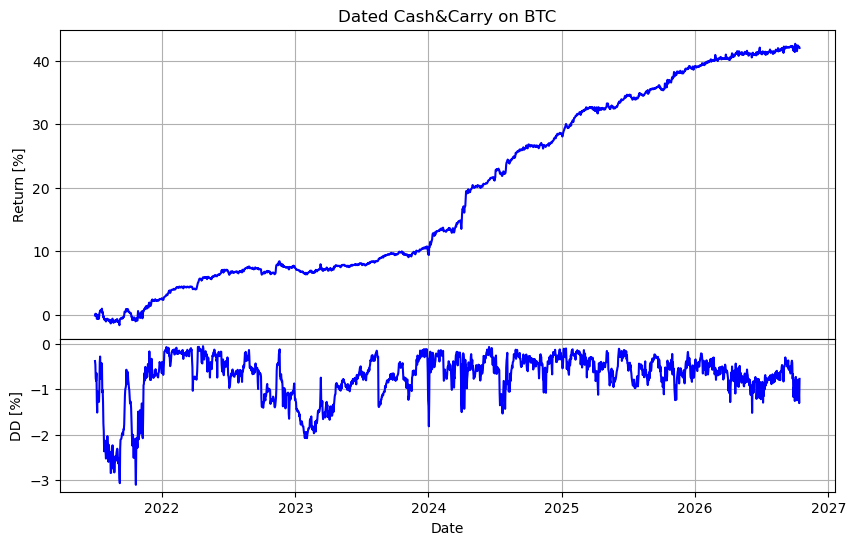

In [ ]:
equity_cc_net = df_cc['equity_tot_net'].copy()
dd_cc_net = ((equity_cc_net/equity_cc_net.cummax() - 1)*100).resample('1D').min()
equity_cc_net = df_cc['equity_tot_net'].resample('1D').last()
equity_cc_net = (equity_cc_net/CAPITAL - 1)*100
#
fig, axes = plt.subplots(nrows = 2, ncols = 1, figsize = [10, 6], height_ratios = (0.67, 0.33), sharex = True)
fig.subplots_adjust(hspace = 0)
axes[0].plot(equity_cc_net, c = 'b')
axes[0].grid()
axes[0].set_ylabel('Return [%]')
axes[0].set_title(f'Dated Cash&Carry on {crypto}')
#
axes[1].plot(dd_cc_net, c = 'b')
axes[1].grid()
axes[1].set_ylabel('DD [%]')
axes[1].set_xlabel('Date')
#
plt.savefig(os.path.join(figures_folder, f'dated_return_{crypto}.png'), bbox_inches = 'tight')
plt.show()

## Perpetual C&C

In [ ]:
# perpetual C&C: spot on 8-hour bars, with the time at the end of the bar -> the interval (00:00, 08:00] has label 08:00, aligned with the funding
df_fund = get_funding(crypto = crypto, date_start = DATE_START_DATA)
spot_8h = df_spot['spot'].resample('8h', label = 'right', closed = 'right').last().rename('Close')
df_perp = pd.concat((spot_8h, df_fund), axis = 1).dropna()

In [ ]:
df_cc_perp = backtest_cc_perp(df = df_perp, date_buy_cry = DATE_BUY_CRY, date_open_cc = DATE_OPEN_CC, mult = MULT, lev = LEV,
                              fee_spot = FEE_SPOT, fee_fut = FEE_FUT, capital = CAPITAL, frac_cap_for_rehedge = FRAC_CAP_FOR_REHEDGE)
df_cc_perp.head()

,Close,fund_rate,funding,port,pl_fut,equity_fut,equity_port,equity_tot_gross,equity_tot_net,rehedge
Time,,,,,,,,,,
2021-07-01 00:00:00,35049.91,-0.000340,0.000000,0.028487,0.000000,0.000000,998.450550,998.450550,996.903199,0
2021-07-01 08:00:00,33355.96,-0.000120,-0.000004,0.028483,0.001447,48.281324,950.076131,998.357454,996.810196,0
2021-07-01 16:00:00,33451.13,-0.000140,-0.000004,0.028479,0.001362,45.568768,952.647043,998.215811,996.668695,0
2021-07-02 00:00:00,33535.06,-0.000246,-0.000007,0.028471,0.001288,43.176577,954.791153,997.967730,996.420862,0
2021-07-02 08:00:00,33371.50,-0.000283,-0.000008,0.028463,0.001434,47.838399,949.851508,997.689908,996.143317,0


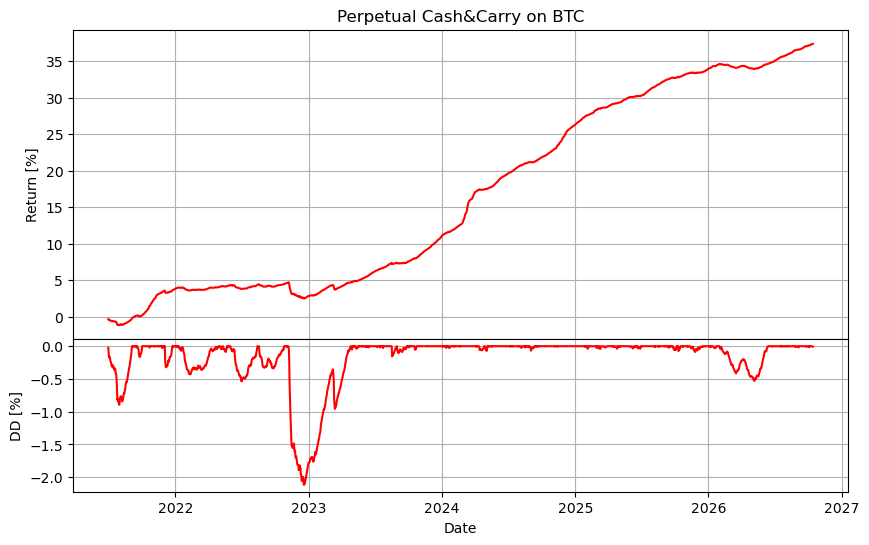

In [ ]:
equity_cc_perp_net = df_cc_perp['equity_tot_net'].copy()
dd_cc_perp_net = ((equity_cc_perp_net/equity_cc_perp_net.cummax() - 1)*100).resample('1D').min()
equity_cc_perp_net = df_cc_perp['equity_tot_net'].resample('1D').last()
equity_cc_perp_net = (equity_cc_perp_net/CAPITAL - 1)*100
#
fig, axes = plt.subplots(nrows = 2, ncols = 1, figsize = [10, 6], height_ratios = (0.67, 0.33), sharex = True)
fig.subplots_adjust(hspace = 0)
axes[0].plot(equity_cc_perp_net, c = 'r')
axes[0].grid()
axes[0].set_ylabel('Return [%]')
axes[0].set_title(f'Perpetual Cash&Carry on {crypto}')
#
axes[1].plot(dd_cc_perp_net, c = 'r')
axes[1].grid()
axes[1].set_ylabel('DD [%]')
axes[1].set_xlabel('Date')
#
plt.savefig(os.path.join(figures_folder, f'perpetual_return_{crypto}.png'), bbox_inches = 'tight')
plt.show()

## Portfolio

In [ ]:
periods_corr = 1
#
df_corr = pd.DataFrame({'equity_exp': equity_cc_net.pct_change(periods = periods_corr),
                        'equity_perp': equity_cc_perp_net.pct_change(periods = periods_corr),
                        'spot': df_spot.resample('1D')['spot'].last().pct_change(periods = periods_corr)}).dropna()
df_corr.corr()

,equity_exp,equity_perp,spot
equity_exp,1.000000,-0.006041,-0.007367
equity_perp,-0.006041,1.000000,0.025628
spot,-0.007367,0.025628,1.000000


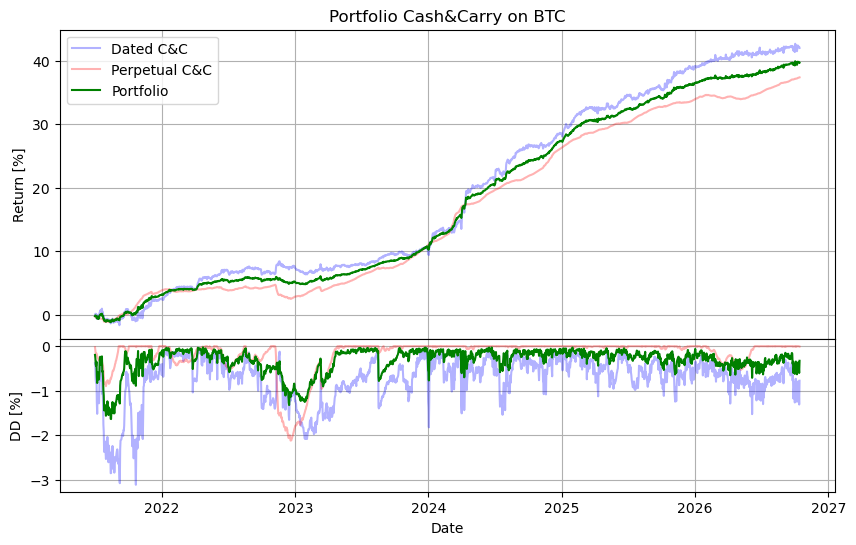

In [ ]:
equity_port, dd_port = get_equity_port(equity_1 = df_cc['equity_tot_net'], equity_2 = df_cc_perp['equity_tot_net'], capital = CAPITAL)
#
fig, axes = plt.subplots(nrows = 2, ncols = 1, figsize = [10, 6], height_ratios = (0.67, 0.33), sharex = True)
fig.subplots_adjust(hspace = 0)
#
axes[0].plot(equity_cc_net, c = 'b', alpha = 0.3, label = 'Dated C&C')
axes[0].plot(equity_cc_perp_net, c = 'r', alpha = 0.3, label = 'Perpetual C&C')
axes[0].plot(equity_port, c = 'g', label = 'Portfolio')
axes[0].legend()
axes[0].grid()
axes[0].set_ylabel('Return [%]')
axes[0].set_title(f'Portfolio Cash&Carry on {crypto}')
#
axes[1].plot(dd_cc_net, c = 'b', alpha = 0.3)
axes[1].plot(dd_cc_perp_net, c = 'r', alpha = 0.3)
axes[1].plot(dd_port, c = 'g')
axes[1].grid()
axes[1].set_ylabel('DD [%]')
axes[1].set_xlabel('Date')
#
plt.savefig(os.path.join(figures_folder, f'portfolio_return_{crypto}.png'), bbox_inches = 'tight')
plt.show()

In [ ]:
# dated C&C
ret_annual_cc = ((equity_cc_net.iloc[-1]/100 + 1)**(365/(equity_cc_net.index[-1] - equity_cc_net.index[0]).days) - 1)*100
print('--- C&C ---')
print(f'CAGR = {ret_annual_cc:.2f}%, max DD = {dd_cc_net.min():.2f}%, avg DD = {dd_cc_net[dd_cc_net != 0].mean():.2f}%, CAGR/(avg DD) = {-ret_annual_cc/dd_cc_net[dd_cc_net != 0].mean():.2f}')
print()
# perpetual C&C
ret_annual_cc_perp = ((equity_cc_perp_net.iloc[-1]/100 + 1)**(365/(equity_cc_perp_net.index[-1] - equity_cc_perp_net.index[0]).days) - 1)*100
print('--- Perpetual C&C ---')
print(f'CAGR = {ret_annual_cc_perp:.2f}%, max DD = {dd_cc_perp_net.min():.2f}%, avg DD = {dd_cc_perp_net[dd_cc_perp_net != 0].mean():.2f}%, CAGR/(avg DD) = {-ret_annual_cc_perp/dd_cc_perp_net[dd_cc_perp_net != 0].mean():.2f}')
print()
# portfolio
ret_annual_port = ((equity_port.iloc[-1]/100 + 1)**(365/(equity_port.index[-1] - equity_port.index[0]).days) - 1)*100
print('--- Portfolio ---')
print(f'CAGR = {ret_annual_port:.2f}%, max DD = {dd_port.min():.2f}%, avg DD = {dd_port[dd_port != 0].mean():.2f}%, CAGR/(avg DD) = {-ret_annual_port/dd_port[dd_port != 0].mean():.2f}')
print()

--- C&C ---
CAGR = 6.85%, max DD = -3.11%, avg DD = -0.73%, CAGR/(avg DD) = 9.42

--- Perpetual C&C ---
CAGR = 6.18%, max DD = -2.12%, avg DD = -0.29%, CAGR/(avg DD) = 21.00

--- Portfolio ---
CAGR = 6.52%, max DD = -1.63%, avg DD = -0.32%, CAGR/(avg DD) = 20.18



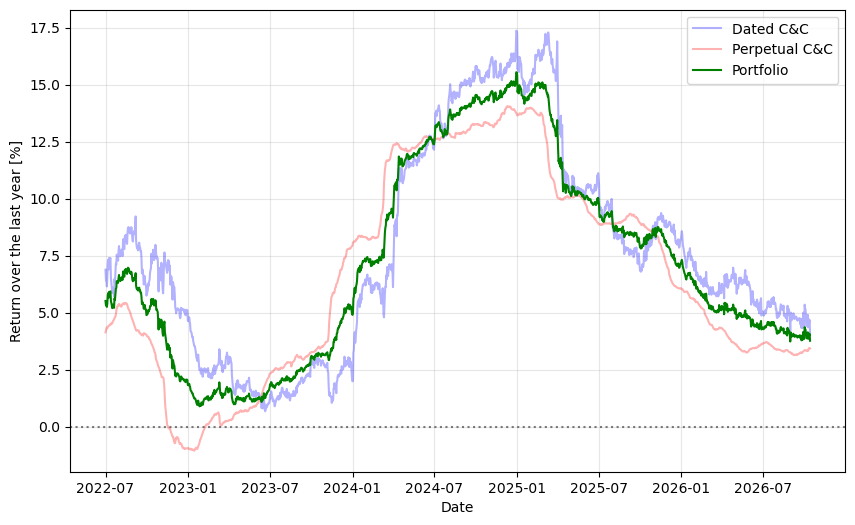

In [ ]:
ret_cc_ann = (1 + equity_cc_net/100).asfreq('1D').ffill()
ret_cc_ann = (ret_cc_ann/ret_cc_ann.shift(365) - 1).dropna()*100
#
ret_cc_perp_ann = (1 + equity_cc_perp_net/100).asfreq('1D').ffill()
ret_cc_perp_ann = (ret_cc_perp_ann/ret_cc_perp_ann.shift(365) - 1).dropna()*100
#
ret_port_ann = (1 + equity_port/100).asfreq('1D').ffill()
ret_port_ann = (ret_port_ann/ret_port_ann.shift(365) - 1).dropna()*100
#
plt.figure(figsize = [10, 6])
plt.plot(ret_cc_ann, c = 'b', alpha = 0.3, label = 'Dated C&C', zorder = 3)
plt.plot(ret_cc_perp_ann, c = 'r', alpha = 0.3, label = 'Perpetual C&C', zorder = 3)
plt.plot(ret_port_ann, c = 'g', label = 'Portfolio', zorder = 3)
plt.axhline(0, c = 'k', alpha = 0.5, ls = ':', zorder = 2)
plt.legend()
plt.grid(zorder = 1, alpha = 0.3)
plt.xlabel('Date')
plt.ylabel('Return over the last year [%]')
plt.title(f'Rolling yearly return on {crypto}')
plt.savefig(os.path.join(figures_folder, f'rolling_return_{crypto}.png'), bbox_inches = 'tight')
plt.show()

# ETH

In [ ]:
crypto = 'ETH'

In [ ]:
# hourly spot (index price), shared by the two strategies
df_spot = get_spot(crypto = crypto, date_start = DATE_START_DATA)

## Dated C&C

In [ ]:
# dated C&C
df_fut, dict_exp = get_data_cc(crypto = crypto, date_start = DATE_START_DATA, df_spot = df_spot)

In [ ]:
# number of days to expiry for each futures
df_days = pd.DataFrame({symb: (dict_exp[symb] - df_fut.index)/pd.Timedelta(value = 1, unit = 'd') for symb in df_fut.columns}, index = df_fut.index)
# return: percentage change between futures and spot, annualized
df_ret = (df_fut/df_spot['spot'].values.reshape(-1, 1) - 1)
df_ret = df_ret/df_days.where(df_days > 1)*365

In [ ]:
df_cc, df_cc_trade = backtest_cc(df_spot = df_spot, df_fut = df_fut, df_ret = df_ret, dict_exp = dict_exp, date_buy_cry = DATE_BUY_CRY,
                                 capital = CAPITAL, fee_spot = FEE_SPOT, fee_fut = FEE_FUT, fee_delivery = FEE_DELIVERY,
                                 mult = MULT, lev = LEV, min_days_left = MIN_DAYS_LEFT,
                                 hours_rolling_before_exp = HOURS_ROLLING_BEFORE_EXPIRY, strategy = 'max_ret')

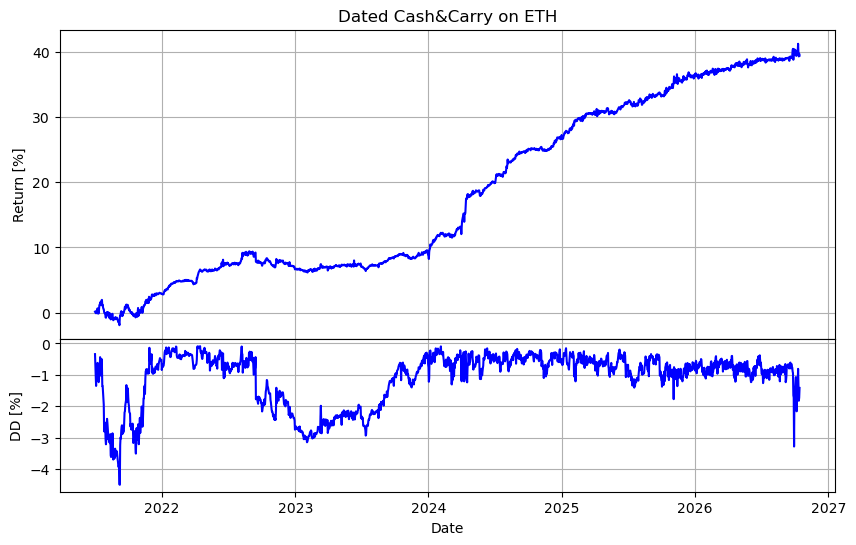

In [ ]:
equity_cc_net = df_cc['equity_tot_net'].copy()
dd_cc_net = ((equity_cc_net/equity_cc_net.cummax() - 1)*100).resample('1D').min()
equity_cc_net = df_cc['equity_tot_net'].resample('1D').last()
equity_cc_net = (equity_cc_net/CAPITAL - 1)*100
#
fig, axes = plt.subplots(nrows = 2, ncols = 1, figsize = [10, 6], height_ratios = (0.67, 0.33), sharex = True)
fig.subplots_adjust(hspace = 0)
axes[0].plot(equity_cc_net, c = 'b')
axes[0].grid()
axes[0].set_ylabel('Return [%]')
axes[0].set_title(f'Dated Cash&Carry on {crypto}')
#
axes[1].plot(dd_cc_net, c = 'b')
axes[1].grid()
axes[1].set_ylabel('DD [%]')
axes[1].set_xlabel('Date')
#
plt.savefig(os.path.join(figures_folder, f'dated_return_{crypto}.png'), bbox_inches = 'tight')
plt.show()

## Perpetual C&C

In [ ]:
# perpetual C&C: spot on 8-hour bars, with the time at the end of the bar -> the interval (00:00, 08:00] has label 08:00, aligned with the funding
df_fund = get_funding(crypto = crypto, date_start = DATE_START_DATA)
spot_8h = df_spot['spot'].resample('8h', label = 'right', closed = 'right').last().rename('Close')
df_perp = pd.concat((spot_8h, df_fund), axis = 1).dropna()

In [ ]:
df_cc_perp = backtest_cc_perp(df = df_perp, date_buy_cry = DATE_BUY_CRY, date_open_cc = DATE_OPEN_CC, mult = MULT, lev = LEV,
                              fee_spot = FEE_SPOT, fee_fut = FEE_FUT, capital = CAPITAL, frac_cap_for_rehedge = FRAC_CAP_FOR_REHEDGE)
df_cc_perp.head()

,Close,fund_rate,funding,port,pl_fut,equity_fut,equity_port,equity_tot_gross,equity_tot_net,rehedge
Time,,,,,,,,,,
2021-07-01 00:00:00,2276.69,0.000100,0.000000,0.438554,0.000000,0.000000,998.450550,998.450550,996.903199,0
2021-07-01 08:00:00,2130.07,0.000100,0.000047,0.438600,0.030204,64.336111,934.249724,998.585835,997.038348,0
2021-07-01 16:00:00,2119.09,0.000100,0.000047,0.438648,0.032634,69.154079,929.533791,998.687870,997.140281,0
2021-07-02 00:00:00,2108.40,-0.000052,-0.000025,0.438623,0.035024,73.844797,924.792870,998.637666,997.090128,0
2021-07-02 08:00:00,2061.24,0.000085,0.000041,0.438664,0.045865,94.538365,904.191881,998.730246,997.182615,0


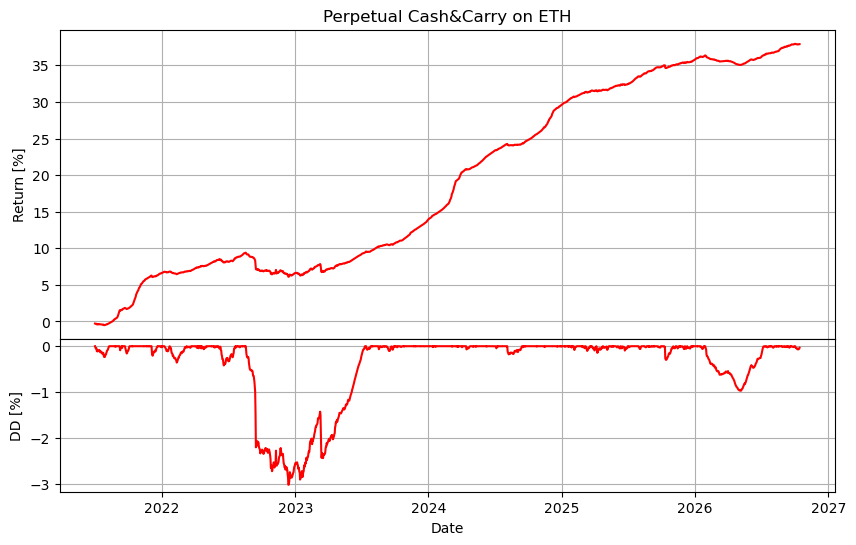

In [ ]:
equity_cc_perp_net = df_cc_perp['equity_tot_net'].copy()
dd_cc_perp_net = ((equity_cc_perp_net/equity_cc_perp_net.cummax() - 1)*100).resample('1D').min()
equity_cc_perp_net = df_cc_perp['equity_tot_net'].resample('1D').last()
equity_cc_perp_net = (equity_cc_perp_net/CAPITAL - 1)*100
#
fig, axes = plt.subplots(nrows = 2, ncols = 1, figsize = [10, 6], height_ratios = (0.67, 0.33), sharex = True)
fig.subplots_adjust(hspace = 0)
axes[0].plot(equity_cc_perp_net, c = 'r')
axes[0].grid()
axes[0].set_ylabel('Return [%]')
axes[0].set_title(f'Perpetual Cash&Carry on {crypto}')
#
axes[1].plot(dd_cc_perp_net, c = 'r')
axes[1].grid()
axes[1].set_ylabel('DD [%]')
axes[1].set_xlabel('Date')
#
plt.savefig(os.path.join(figures_folder, f'perpetual_return_{crypto}.png'), bbox_inches = 'tight')
plt.show()

## Portfolio

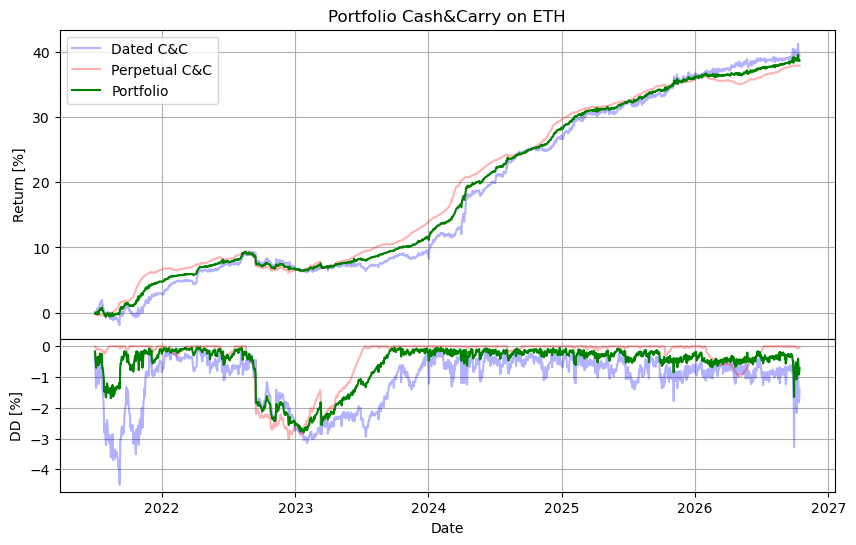

In [ ]:
equity_port, dd_port = get_equity_port(equity_1 = df_cc['equity_tot_net'], equity_2 = df_cc_perp['equity_tot_net'], capital = CAPITAL)
#
fig, axes = plt.subplots(nrows = 2, ncols = 1, figsize = [10, 6], height_ratios = (0.67, 0.33), sharex = True)
fig.subplots_adjust(hspace = 0)
#
axes[0].plot(equity_cc_net, c = 'b', alpha = 0.3, label = 'Dated C&C')
axes[0].plot(equity_cc_perp_net, c = 'r', alpha = 0.3, label = 'Perpetual C&C')
axes[0].plot(equity_port, c = 'g', label = 'Portfolio')
axes[0].legend()
axes[0].grid()
axes[0].set_ylabel('Return [%]')
axes[0].set_title(f'Portfolio Cash&Carry on {crypto}')
#
axes[1].plot(dd_cc_net, c = 'b', alpha = 0.3)
axes[1].plot(dd_cc_perp_net, c = 'r', alpha = 0.3)
axes[1].plot(dd_port, c = 'g')
axes[1].grid()
axes[1].set_ylabel('DD [%]')
axes[1].set_xlabel('Date')
#
plt.savefig(os.path.join(figures_folder, f'portfolio_return_{crypto}.png'), bbox_inches = 'tight')
plt.show()

In [ ]:
# dated C&C
ret_annual_cc = ((equity_cc_net.iloc[-1]/100 + 1)**(365/(equity_cc_net.index[-1] - equity_cc_net.index[0]).days) - 1)*100
print('--- C&C ---')
print(f'CAGR = {ret_annual_cc:.2f}%, max DD = {dd_cc_net.min():.2f}%, avg DD = {dd_cc_net[dd_cc_net != 0].mean():.2f}%, CAGR/(avg DD) = {-ret_annual_cc/dd_cc_net[dd_cc_net != 0].mean():.2f}')
print()
# perpetual C&C
ret_annual_cc_perp = ((equity_cc_perp_net.iloc[-1]/100 + 1)**(365/(equity_cc_perp_net.index[-1] - equity_cc_perp_net.index[0]).days) - 1)*100
print('--- Perpetual C&C ---')
print(f'CAGR = {ret_annual_cc_perp:.2f}%, max DD = {dd_cc_perp_net.min():.2f}%, avg DD = {dd_cc_perp_net[dd_cc_perp_net != 0].mean():.2f}%, CAGR/(avg DD) = {-ret_annual_cc_perp/dd_cc_perp_net[dd_cc_perp_net != 0].mean():.2f}')
print()
# portfolio
ret_annual_port = ((equity_port.iloc[-1]/100 + 1)**(365/(equity_port.index[-1] - equity_port.index[0]).days) - 1)*100
print('--- Portfolio ---')
print(f'CAGR = {ret_annual_port:.2f}%, max DD = {dd_port.min():.2f}%, avg DD = {dd_port[dd_port != 0].mean():.2f}%, CAGR/(avg DD) = {-ret_annual_port/dd_port[dd_port != 0].mean():.2f}')
print()

--- C&C ---
CAGR = 6.48%, max DD = -4.50%, avg DD = -1.10%, CAGR/(avg DD) = 5.89

--- Perpetual C&C ---
CAGR = 6.26%, max DD = -3.02%, avg DD = -0.58%, CAGR/(avg DD) = 10.85

--- Portfolio ---
CAGR = 6.37%, max DD = -2.80%, avg DD = -0.60%, CAGR/(avg DD) = 10.58



AttributeError: module 'matplotlib.pyplot' has no attribute 'set_title'

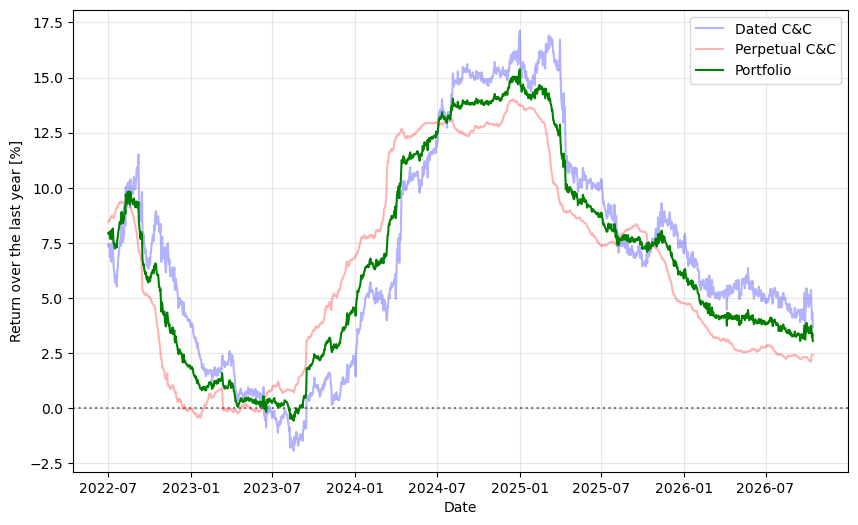

In [ ]:
ret_cc_ann = (1 + equity_cc_net/100).asfreq('1D').ffill()
ret_cc_ann = (ret_cc_ann/ret_cc_ann.shift(365) - 1).dropna()*100
#
ret_cc_perp_ann = (1 + equity_cc_perp_net/100).asfreq('1D').ffill()
ret_cc_perp_ann = (ret_cc_perp_ann/ret_cc_perp_ann.shift(365) - 1).dropna()*100
#
ret_port_ann = (1 + equity_port/100).asfreq('1D').ffill()
ret_port_ann = (ret_port_ann/ret_port_ann.shift(365) - 1).dropna()*100
#
plt.figure(figsize = [10, 6])
plt.plot(ret_cc_ann, c = 'b', alpha = 0.3, label = 'Dated C&C', zorder = 3)
plt.plot(ret_cc_perp_ann, c = 'r', alpha = 0.3, label = 'Perpetual C&C', zorder = 3)
plt.plot(ret_port_ann, c = 'g', label = 'Portfolio', zorder = 3)
plt.axhline(0, c = 'k', alpha = 0.5, ls = ':', zorder = 2)
plt.legend()
plt.grid(zorder = 1, alpha = 0.3)
plt.xlabel('Date')
plt.ylabel('Return over the last year [%]')
plt.title(f'Rolling yearly return on {crypto}')
plt.savefig(os.path.join(figures_folder, f'rolling_return_{crypto}.png'), bbox_inches = 'tight')
plt.show()